# Experimento binario: solo imágenes con CNN

Primer baseline de aprendizaje profundo para clasificar morfología MaNGA usando únicamente los cutouts RGB: `temprana = 0.0` y `tardia = 1.0`.

La cohorte y los splits persistidos permanecen fijos. La arquitectura es una CNN compacta entrenada desde cero y produce un único logit por galaxia.

In [1]:
from __future__ import annotations

import copy
import json
import random
import sys
import time
from pathlib import Path
from typing import Any, Mapping

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay, balanced_accuracy_score, f1_score
from torch import nn
from tqdm.auto import tqdm


def project_root(start: Path = Path.cwd()) -> Path:
    for candidate in (start.resolve(), *start.resolve().parents):
        if (candidate / "src").is_dir() and (candidate / "data").is_dir():
            return candidate
    raise FileNotFoundError("No se encontró la raíz del proyecto.")


ROOT = project_root()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.dataloader.multimodal import build_dataloaders
from src.evaluate import evaluate_binary_classifier

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Proyecto: {ROOT}")
print(f"Dispositivo: {DEVICE}")

/Users/juliovelazquez/Documents/maestria/proyecto_integrador/clasificacion-galaxias/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Proyecto: /Users/juliovelazquez/Documents/maestria/proyecto_integrador/clasificacion-galaxias
Dispositivo: cpu


## Configuración e invariantes

- El split `data/processed/splits_seed42_obj-label.csv` es fijo: no se regenera dentro de un experimento.
- Comparaciones de modalidades o arquitecturas mantienen la misma semilla, cohorte y protocolo de selección.
- La selección de checkpoints usa solo validación; `test` se consulta una única vez para el modelo seleccionado.
- Se usa una salida logit por galaxia y `BCEWithLogitsLoss`.

In [2]:
CONFIG: dict[str, Any] = {
    "experiment_name": "experimento_binario_imagenes_cnn",
    "seed": 42,
    "data": {
        "project_root": ROOT,
        "manifest": "data/galaxy_manifest.csv",
        "splits": "data/processed/splits_seed42_obj-label.csv",
        "modalities": ["image"],
        "image": {
            "fov_column": "fov_0",
            "size": 256,
            "normalization": "none",
        },
    },
    "training": {
        "batch_size": 32,
        "num_workers": 0,
        "pin_memory": DEVICE.type == "cuda",
        "epochs": 30,
        "learning_rate": 3e-4,
        "weight_decay": 1e-4,
        "max_grad_norm": 1.0,
        "early_stopping_patience": 8,
    },
    "selection_metric": "roc_auc",
}

RUN_DIR = ROOT / "models" / "experiments" / CONFIG["experiment_name"]
CHECKPOINT_PATH = RUN_DIR / "best_model.pt"
RESULTS_PATH = RUN_DIR / "results.json"
CONFIG_PATH = RUN_DIR / "config.json"

In [3]:
def set_seed(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


set_seed(CONFIG["seed"])
train_loader, validation_loader, test_loader = build_dataloaders(CONFIG)
loaders = {"train": train_loader, "validation": validation_loader, "test": test_loader}

for split_name, loader in loaders.items():
    labels = loader.dataset.frame["label"].value_counts()
    print(f"{split_name:10s} n={len(loader.dataset):5d}  temprana={labels.get('temprana', 0):5d}  tardia={labels.get('tardia', 0):5d}")

sample_batch = next(iter(train_loader))
for key, value in sample_batch.items():
    if isinstance(value, torch.Tensor):
        print(f"{key:16s} {tuple(value.shape)} {value.dtype}")
    else:
        print(f"{key:16s} {type(value).__name__}")

train      n= 6545  temprana= 2467  tardia= 4078
validation n= 1403  temprana=  529  tardia=  874
test       n= 1403  temprana=  528  tardia=  875
id               list
label            (32,) torch.float32
image            (32, 3, 256, 256) torch.float32


## Arquitectura: CNN solo imágenes

La red usa cuatro bloques `Conv2d -> BatchNorm2d -> ReLU -> MaxPool2d` con 32, 64, 128 y 256 canales. Cada bloque contiene dos convoluciones; al final, `AdaptiveAvgPool2d` y `Dropout -> Linear(256, 1)` producen un logit binario.

Es una línea base adecuada: aprende rasgos espaciales sin pesos externos, tiene capacidad moderada para los cutouts de $256 \times 256$ y permite verificar el pipeline antes de explorar transfer learning.

In [4]:
class ImageOnlyCNN(nn.Module):
    def __init__(self, dropout: float = 0.30) -> None:
        super().__init__()

        def conv_block(in_channels: int, out_channels: int) -> nn.Sequential:
            return nn.Sequential(
                nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1, bias=False),
                nn.BatchNorm2d(out_channels),
                nn.ReLU(inplace=True),
                nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1, bias=False),
                nn.BatchNorm2d(out_channels),
                nn.ReLU(inplace=True),
                nn.MaxPool2d(kernel_size=2),
            )

        self.features = nn.Sequential(
            conv_block(3, 32),
            conv_block(32, 64),
            conv_block(64, 128),
            conv_block(128, 256),
        )
        self.classifier = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),
            nn.Flatten(),
            nn.Dropout(dropout),
            nn.Linear(256, 1),
        )

    def forward(self, batch: Mapping[str, torch.Tensor]) -> torch.Tensor:
        return self.classifier(self.features(batch["image"])).squeeze(1)


def build_model(config: Mapping[str, Any], batch: Mapping[str, Any]) -> nn.Module:
    if "image" not in batch:
        raise ValueError("Este experimento requiere batch['image'].")
    return ImageOnlyCNN()


model = build_model(CONFIG, sample_batch).to(DEVICE)
with torch.no_grad():
    smoke_logits = model({"image": sample_batch["image"].to(DEVICE)})
assert smoke_logits.shape == sample_batch["label"].shape

parameter_count = sum(parameter.numel() for parameter in model.parameters() if parameter.requires_grad)
print(model)
print(f"Parámetros entrenables: {parameter_count:,}")
print(f"Logits de smoke test: {tuple(smoke_logits.shape)}")

ImageOnlyCNN(
  (features): Sequential(
    (0): Sequential(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (5): ReLU(inplace=True)
      (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (1): Sequential(
      (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (5): ReLU(i

In [5]:
def move_batch_to_device(batch: Mapping[str, Any], device: torch.device) -> dict[str, Any]:
    return {
        key: value.to(device, non_blocking=True) if isinstance(value, torch.Tensor) else value
        for key, value in batch.items()
    }


def logits_from_model(model: nn.Module, batch: Mapping[str, Any]) -> torch.Tensor:
    logits = model(batch)
    expected_shape = batch["label"].shape
    if logits.shape != expected_shape:
        raise ValueError(f"El modelo devolvió {tuple(logits.shape)}; se esperaba {tuple(expected_shape)}.")
    if not torch.isfinite(logits).all():
        raise FloatingPointError("El modelo produjo logits no finitos.")
    return logits


def train_epoch(
    model: nn.Module,
    loader: torch.utils.data.DataLoader,
    optimizer: torch.optim.Optimizer,
    criterion: nn.Module,
    device: torch.device,
    epoch: int,
    total_epochs: int,
    max_grad_norm: float,
) -> float:
    model.train()
    total_loss = 0.0
    progress = tqdm(
        loader,
        desc=f"Epoch {epoch:02d}/{total_epochs}",
        unit="batch",
        leave=False,
    )
    for batch in progress:
        batch = move_batch_to_device(batch, device)
        optimizer.zero_grad(set_to_none=True)
        loss = criterion(logits_from_model(model, batch), batch["label"])
        if not torch.isfinite(loss):
            raise FloatingPointError("La pérdida de entrenamiento dejó de ser finita.")
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=max_grad_norm)
        optimizer.step()
        total_loss += loss.item() * batch["label"].numel()
        progress.set_postfix(train_loss=f"{total_loss / len(loader.dataset):.4f}")
    return total_loss / len(loader.dataset)


@torch.no_grad()
def evaluate_epoch(
    model: nn.Module,
    loader: torch.utils.data.DataLoader,
    criterion: nn.Module,
    device: torch.device,
) -> tuple[float, np.ndarray, np.ndarray, np.ndarray]:
    model.eval()
    total_loss = 0.0
    all_true, all_pred, all_proba = [], [], []
    for batch in loader:
        # Preserve labels on CPU: MPS integer transfers can corrupt metric targets.
        labels_cpu = batch["label"].to(torch.int64).numpy().copy()
        batch = move_batch_to_device(batch, device)
        logits = logits_from_model(model, batch)
        loss = criterion(logits, batch["label"])
        if not torch.isfinite(loss):
            raise FloatingPointError("La pérdida de validación dejó de ser finita.")
        total_loss += loss.item() * batch["label"].numel()
        probabilities_cpu = torch.sigmoid(logits).detach().cpu().numpy().copy()
        all_true.append(labels_cpu)
        all_pred.append((probabilities_cpu >= 0.5).astype(np.int64, copy=False))
        all_proba.append(probabilities_cpu.astype(np.float64, copy=False))

    y_true = np.concatenate(all_true).astype(np.int64, copy=False).reshape(-1)
    y_pred = np.concatenate(all_pred).astype(np.int64, copy=False).reshape(-1)
    y_proba = np.concatenate(all_proba).astype(np.float64, copy=False).reshape(-1)
    observed_labels = np.unique(y_true)
    if not np.isin(y_true, [0, 1]).all():
        raise ValueError(
            "Las etiquetas de evaluación deben pertenecer a {0, 1}. "
            f"Valores observados: {observed_labels.tolist()}."
        )
    if observed_labels.size != 2:
        raise ValueError(
            "Validación debe contener ambas clases para calcular ROC-AUC. "
            f"Valores observados: {observed_labels.tolist()}."
        )
    return total_loss / len(loader.dataset), y_true, y_pred, y_proba

In [6]:
def fit(
    model: nn.Module,
    train_loader: torch.utils.data.DataLoader,
    validation_loader: torch.utils.data.DataLoader,
    config: Mapping[str, Any],
    device: torch.device,
    checkpoint_path: Path,
) -> pd.DataFrame:
    training_config = config["training"]
    criterion = nn.BCEWithLogitsLoss()
    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=training_config["learning_rate"],
        weight_decay=training_config["weight_decay"],
    )
    history: list[dict[str, float]] = []
    best_score = float("-inf")
    best_state: dict[str, torch.Tensor] | None = None
    epochs_without_improvement = 0

    for epoch in range(1, training_config["epochs"] + 1):
        started_at = time.perf_counter()
        train_loss = train_epoch(
            model,
            train_loader,
            optimizer,
            criterion,
            device,
            epoch,
            training_config["epochs"],
            training_config["max_grad_norm"],
        )
        validation_loss, y_true, y_pred, y_proba = evaluate_epoch(
            model, validation_loader, criterion, device
        )
        metrics = evaluate_binary_classifier(y_true, y_pred, y_proba)
        score = float(metrics[config["selection_metric"]])
        if not np.isfinite(score):
            raise FloatingPointError("La métrica de selección no es finita.")
        history.append(
            {
                "epoch": epoch,
                "train_loss": train_loss,
                "validation_loss": validation_loss,
                "validation_accuracy": float(metrics["accuracy"]),
                "validation_balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
                "validation_f1": f1_score(y_true, y_pred, zero_division=0),
                "validation_roc_auc": float(metrics["roc_auc"]),
                "seconds": time.perf_counter() - started_at,
            }
        )
        print(
            f"[{epoch:02d}/{training_config['epochs']}] "
            f"train_loss={train_loss:.4f} val_loss={validation_loss:.4f} "
            f"val_auc={metrics['roc_auc']:.4f}"
        )

        if score > best_score:
            best_score = score
            best_state = copy.deepcopy(model.state_dict())
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1
            if epochs_without_improvement >= training_config["early_stopping_patience"]:
                print("Early stopping por validación.")
                break

    if best_state is None:
        raise RuntimeError("No se obtuvo un checkpoint de validación.")
    checkpoint_path.parent.mkdir(parents=True, exist_ok=True)
    model.load_state_dict(best_state)
    torch.save({"model_state_dict": best_state, "config": dict(config)}, checkpoint_path)
    return pd.DataFrame(history)


# Ejecutar esta celda inicia el entrenamiento y selecciona el mejor checkpoint por ROC-AUC de validación.
history = fit(model, train_loader, validation_loader, CONFIG, DEVICE, CHECKPOINT_PATH)
history.tail()

Epoch 01/30:   0%|          | 0/205 [00:00<?, ?batch/s]

[01/30] train_loss=0.4350 val_loss=0.4701 val_auc=0.8928


[02/30] train_loss=0.3976 val_loss=0.4563 val_auc=0.8998


[03/30] train_loss=0.3744 val_loss=0.4087 val_auc=0.9101


[04/30] train_loss=0.3569 val_loss=0.6244 val_auc=0.8786


[05/30] train_loss=0.3433 val_loss=0.3789 val_auc=0.9128


... (22 outputs left out)

[28/30] train_loss=0.2630 val_loss=0.2556 val_auc=0.9596


[29/30] train_loss=0.2548 val_loss=0.2766 val_auc=0.9584


[30/30] train_loss=0.2568 val_loss=0.2511 val_auc=0.9611


,epoch,train_loss,validation_loss,validation_accuracy,validation_balanced_accuracy,validation_f1,validation_roc_auc,seconds
25,26,0.257037,0.280106,0.891661,0.883569,0.913341,0.950191,696.849719
26,27,0.258284,0.281118,0.886671,0.875460,0.910119,0.950589,699.950771
27,28,0.263007,0.255573,0.898076,0.899910,0.916031,0.959612,700.900344
28,29,0.254785,0.276577,0.885246,0.894090,0.903070,0.958384,698.489554
29,30,0.256789,0.251131,0.896650,0.886081,0.918033,0.961059,690.973016


## Evaluación final y persistencia

Ejecute esta sección solo después de decidir la arquitectura e hiperparámetros usando validación. El split de `test` no participa en selección, calibración ni early stopping.

test_loss=0.2411  test_accuracy=0.9009  test_auc=0.9634
              precision    recall  f1-score      support
0              0.869070  0.867424  0.868246   528.000000
1              0.920091  0.921143  0.920617   875.000000
accuracy       0.900927  0.900927  0.900927     0.900927
macro avg      0.894581  0.894284  0.894432  1403.000000
weighted avg   0.900890  0.900927  0.900908  1403.000000


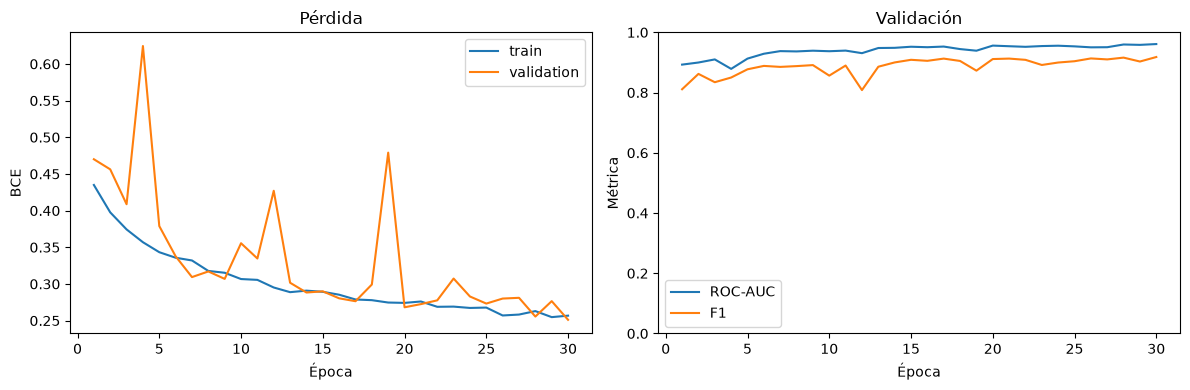

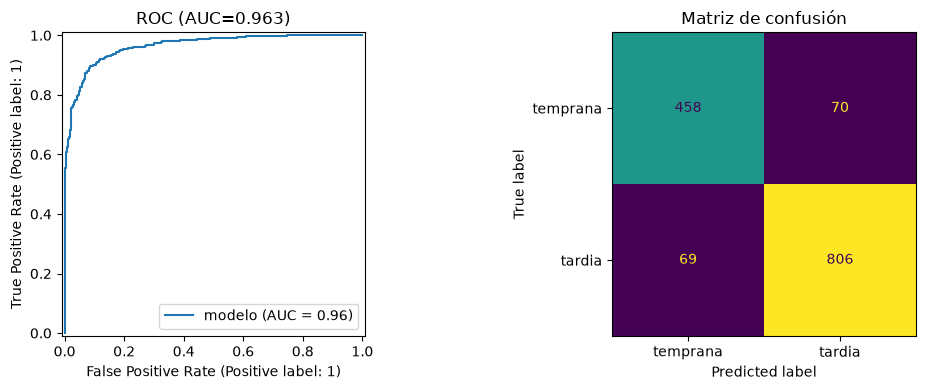

In [7]:
def plot_history(history: pd.DataFrame) -> None:
    figure, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(history["epoch"], history["train_loss"], label="train")
    axes[0].plot(history["epoch"], history["validation_loss"], label="validation")
    axes[0].set(title="Pérdida", xlabel="Época", ylabel="BCE")
    axes[0].legend()
    axes[1].plot(history["epoch"], history["validation_roc_auc"], label="ROC-AUC")
    axes[1].plot(history["epoch"], history["validation_f1"], label="F1")
    axes[1].set(title="Validación", xlabel="Época", ylabel="Métrica", ylim=(0, 1))
    axes[1].legend()
    figure.tight_layout()


def plot_binary_evaluation(y_true: np.ndarray, y_proba: np.ndarray, metrics: Mapping[str, Any]) -> None:
    figure, axes = plt.subplots(1, 2, figsize=(11, 4))
    RocCurveDisplay.from_predictions(y_true, y_proba, ax=axes[0], name="modelo")
    axes[0].set_title(f"ROC (AUC={metrics['roc_auc']:.3f})")
    ConfusionMatrixDisplay(
        confusion_matrix=metrics["confusion_matrix"],
        display_labels=["temprana", "tardia"],
    ).plot(ax=axes[1], colorbar=False)
    axes[1].set_title("Matriz de confusión")
    figure.tight_layout()


def to_jsonable(value: Any) -> Any:
    if isinstance(value, Path):
        return str(value)
    if isinstance(value, np.ndarray):
        return value.tolist()
    if isinstance(value, np.generic):
        return value.item()
    if isinstance(value, Mapping):
        return {str(key): to_jsonable(item) for key, item in value.items()}
    if isinstance(value, (list, tuple)):
        return [to_jsonable(item) for item in value]
    return value


def save_run_artifacts(
    config: Mapping[str, Any], history: pd.DataFrame, test_metrics: Mapping[str, Any]
) -> None:
    RUN_DIR.mkdir(parents=True, exist_ok=True)
    with CONFIG_PATH.open("w", encoding="utf-8") as file:
        json.dump(to_jsonable(config), file, indent=2)
    history.to_csv(RUN_DIR / "history.csv", index=False)
    with RESULTS_PATH.open("w", encoding="utf-8") as file:
        json.dump(to_jsonable(test_metrics), file, indent=2)


# Después de seleccionar el experimento con validación:
criterion = nn.BCEWithLogitsLoss()
test_loss, y_test, y_test_pred, y_test_proba = evaluate_epoch(model, test_loader, criterion, DEVICE)
test_metrics = evaluate_binary_classifier(y_test, y_test_pred, y_test_proba)
print(f"test_loss={test_loss:.4f}  test_accuracy={test_metrics['accuracy']:.4f}  test_auc={test_metrics['roc_auc']:.4f}")
print(pd.DataFrame(test_metrics["report"]).T)
plot_history(history)
plot_binary_evaluation(y_test, y_test_proba, test_metrics)
save_run_artifacts(CONFIG, history, {"test_loss": test_loss, **test_metrics})

In [8]:
# Guarda
RUN_DIR.mkdir(parents=True, exist_ok=True)

experiment_data = {
    "model_state_dict": {
        name: tensor.detach().cpu()
        for name, tensor in model.state_dict().items()
    },
    "config": to_jsonable(CONFIG),
    "device": str(DEVICE),
    "parameter_count": sum(parameter.numel() for parameter in model.parameters()),
    "history": history.to_dict(orient="records"),
    "test_metrics": to_jsonable(
        {"test_loss": test_loss, **test_metrics}
    ),
}

checkpoint_path = RUN_DIR / "experiment_checkpoint.pt"
torch.save(experiment_data, checkpoint_path)

with (RUN_DIR / "config.json").open("w", encoding="utf-8") as file:
    json.dump(to_jsonable(CONFIG), file, indent=2)

history.to_csv(RUN_DIR / "history.csv", index=False)

with (RUN_DIR / "test_metrics.json").open("w", encoding="utf-8") as file:
    json.dump(
        to_jsonable({"test_loss": test_loss, **test_metrics}),
        file,
        indent=2,
    )

print(f"Modelo y resultados guardados en: {RUN_DIR}")
print(f"Checkpoint: {checkpoint_path}")

Modelo y resultados guardados en: /Users/juliovelazquez/Documents/maestria/proyecto_integrador/clasificacion-galaxias/models/experiments/experimento_binario_imagenes_cnn
Checkpoint: /Users/juliovelazquez/Documents/maestria/proyecto_integrador/clasificacion-galaxias/models/experiments/experimento_binario_imagenes_cnn/experiment_checkpoint.pt


In [10]:
history.validation_roc_auc.max()

0.961059466287153